In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

In [11]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.shape

(150, 6)

In [12]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [13]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

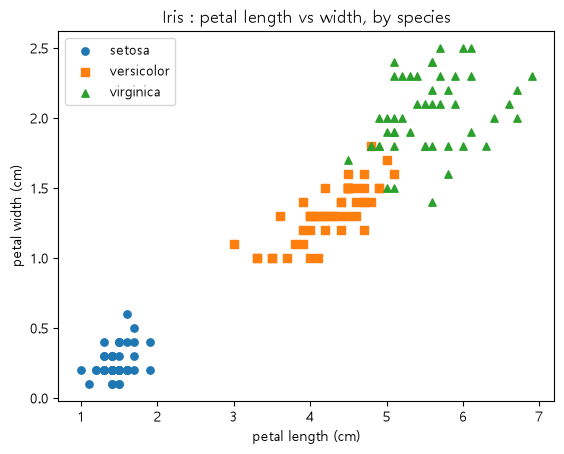

In [14]:
markers = {"setosa": "o", "versicolor": "s", "virginica": "^"}
for name, g in df.groupby("species"):
    plt.scatter(g["petal length (cm)"], g["petal width (cm)"],
        marker=markers[name], label=name, s=28)
plt.xlabel("petal length (cm)")
plt.ylabel("petal width (cm)")
plt.title("Iris : petal length vs width, by species")
plt.legend()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
X = df[iris.feature_names] # feature : 측정값 네 열
y = df["species"] # label : 품종
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
print("training :", len(X_train), " test :", len(X_test))

training : 120  test : 30


In [16]:
import numpy as np
def hand_rule(X): # 그림을 보고 사람이 정한 기준 두 개
    pl = X["petal length (cm)"]
    pw = X["petal width (cm)"]
    return np.where(pl <= 2.5, "setosa",
        np.where(pw <= 1.7, "versicolor", "virginica"))
print("training accuracy :", round((hand_rule(X_train) == y_train).mean(), 3))
print("test accuracy :", round((hand_rule(X_test) == y_test).mean(), 3))

training accuracy : 0.958
test accuracy : 0.967


In [17]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=2, random_state=0)
model.fit(X_train, y_train)

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

DecisionTreeClassifier(max_depth=2, random_state=0)

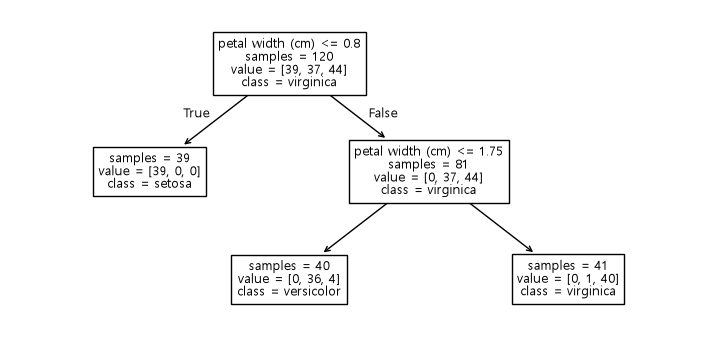

In [18]:
from sklearn.tree import plot_tree
plt.figure(figsize=(9, 4.2))
plot_tree(model, feature_names=iris.feature_names,
    class_names=iris.target_names,
    impurity=False, fontsize=9)
plt.show()

In [20]:
new = pd.DataFrame([[6.0, 2.9, 4.5, 1.5]], columns=iris.feature_names)
print(model.predict(new)[0])

versicolor


In [21]:
print(model.predict_proba(new).round(2)) # setosa, versicolor, virginica 순서

[[0.  0.9 0.1]]


In [22]:
print("training accuracy :", round(model.score(X_train, y_train), 3))
print("test accuracy :", round(model.score(X_test, y_test), 3))

training accuracy : 0.958
test accuracy : 0.967


In [23]:
from sklearn.metrics import confusion_matrix
pred = model.predict(X_test)
pd.DataFrame(confusion_matrix(y_test, pred),
    index=["true_" + n for n in iris.target_names],
    columns=["pred_" + n for n in iris.target_names])

,pred_setosa,pred_versicolor,pred_virginica
true_setosa,11,0,0
true_versicolor,0,13,0
true_virginica,0,1,5


In [24]:
import joblib
joblib.dump(model, "iris_model.pkl")

['iris_model.pkl']

In [25]:
loaded = joblib.load("iris_model.pkl")
print(loaded.predict(new)[0])

versicolor
